**Name:** Fredrick Kimutai 
**Student number:** 2024658 
**GitHub repository:** https://github.com/2024658/data_exploration_ca_1

# Electricity Generation Across Countries
**Domain:** Energy 
**Data:** Our World in Data energy dataset 
**Tools:** pandas, matplotlib, seaborn, scikit-learn

**Research question:** How do countries' electricity mixes differ, and which measures (energy sources, demand, income, carbon intensity) explain the main differences?

Put **owid_energy.csv** in the same folder as this notebook, then choose **Run All**.

## 1. Data preparation

### 1.1 Load the data and examine


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

raw = pd.read_csv("owid_energy.csv")
print("Rows and columns:", raw.shape)
print(raw.dtypes.value_counts())
raw[["country", "year", "iso_code", "population", "gdp"]].head()

Rows and columns: (19494, 130)
float64    127
str          2
int64        1
Name: count, dtype: int64


,country,year,iso_code,population,gdp
0,ASEAN (Ember),2000,NaN,NaN,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN


The file has one row per country per year and 130 columns, almost all numeric.

### 1.2 Keep real countries and recent years
Rows like "World" or "Asia" are totals, not countries, so they would double count. They have a blank **iso_code**or one that starts with **OWID**. I also keep only 2000 to 2024, because electricity data is patchy before that.

In [9]:
iso = raw["iso_code"].fillna("")                     
df = raw[(iso != "") & (~iso.str.startswith("OWID"))]
df = df[(df["year"] >= 2000) & (df["year"] <= 2024)]
print("Countries:", df["country"].nunique(), "| rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())

Countries: 220 | rows: 5468
Duplicate rows: 0


### 1.3 Choosing Columns and Handling Missing Values
From the 130 raw attributes, I retain **14 domain-relevant columns** covering demographics and economic scale **(country, year, population, gdp)**, electricity generation shares (coal, gas, oil, nuclear, hydro, solar, wind, renewables), per-capita demand, and carbon intensity. Missing values are handled via **listwise deletion (dropna())** rather than imputation A blank electricity share does not  mean 0%, and filling with an average would distort very different national energy profiles. Because gdp has the highest missingness (**30.7%**, including 2023–2024), dropping incomplete rows reduces the dataset from **5,468 to 3,547 rows** across **159 countries (2000–2022)**a trade-off that preserves data accuracy while still exceeding the 3,000-row requirement.

In [13]:
columns = ["country", "year", "population", "gdp",
           "coal_electricity_share_pct", "gas_electricity_share_pct",
           "oil_electricity_share_pct", "nuclear_electricity_share_pct",
           "hydro_electricity_share_pct", "solar_electricity_share_pct",
           "wind_electricity_share_pct", "renewables_electricity_share_pct",
           "electricity_demand_per_capita_kwh",
           "electricity_carbon_intensity_gco2eq_per_kwh"]
df = df[columns].copy()

print("Missing values per column (%):")
print((df.isna().mean() * 100).round(1).sort_values(ascending=False))

df = df.dropna()          # remove any row with a missing value
print("Rows after dropping missing values:", len(df))

Missing values per column (%):
country                                        0.0
year                                           0.0
population                                     0.0
gdp                                            0.0
coal_electricity_share_pct                     0.0
gas_electricity_share_pct                      0.0
oil_electricity_share_pct                      0.0
nuclear_electricity_share_pct                  0.0
hydro_electricity_share_pct                    0.0
solar_electricity_share_pct                    0.0
wind_electricity_share_pct                     0.0
renewables_electricity_share_pct               0.0
electricity_demand_per_capita_kwh              0.0
electricity_carbon_intensity_gco2eq_per_kwh    0.0
dtype: float64
Rows after dropping missing values: 3547


### 1.4 Created New Features

I createdd six additional features to support comparisons, visualisation and encoding:

- **Gdp_per_capita**: Divides GDP by population to compare economic output per person across countries.
- **Wind_solar_share_pct**: Combines wind and solar electricity shares into one measure.
- **Log_demand and log_gdp_pc**: Reduce right-skewness in electricity demand per person and GDP per capita before correlation analysis and PCA. Demand uses `log(demand + 1)` to handle zeros; GDP per capita must be positive.
- **Period**: Groups years into three ordered periods (2000–2009, 2010–2019, 2020–2024) for ordinal encoding. After cleaning, the available data ends in 2022.
- **Dominant_source**: Identifies the largest share among the selected source categories for each country-year, treating wind and solar as a combined category. This supports visual grouping and one hot encoding(does not include other renewables and bioenergy)

In [15]:
df["gdp_per_capita"] = df["gdp"] / df["population"]
df["wind_solar_share_pct"] = df["wind_electricity_share_pct"] + df["solar_electricity_share_pct"]

# Log transforms: demand and income are very skewed
df["log_demand"] = np.log(df["electricity_demand_per_capita_kwh"] + 1)
df["log_gdp_pc"] = np.log(df["gdp_per_capita"])

# Time period (grouping of years)
df["period"] = pd.cut(df["year"], bins=[1999, 2009, 2019, 2024],
                      labels=["2000-2009", "2010-2019", "2020-2024"])

# Dominant source = the source with the biggest share (a category)
sources = {"coal_electricity_share_pct": "Coal", "gas_electricity_share_pct": "Gas",
           "oil_electricity_share_pct": "Oil", "nuclear_electricity_share_pct": "Nuclear",
           "hydro_electricity_share_pct": "Hydro", "wind_solar_share_pct": "Wind & solar"}
df["dominant_source"] = df[list(sources)].idxmax(axis=1).map(sources)
print(df["dominant_source"].value_counts())

dominant_source
Hydro           1133
Gas              857
Oil              786
Coal             566
Nuclear          171
Wind & solar      34
Name: count, dtype: int64


### 1.5 Outliers
I use the IQR rule (values far outside the middle 50 %) on electricity demand per person.

Outliers: 225 of 3547
country
Bahrain    23
Canada     23
Finland    23
Iceland    23
Kuwait     23
Norway     23
Qatar      23
Sweden     23
Name: count, dtype: int64


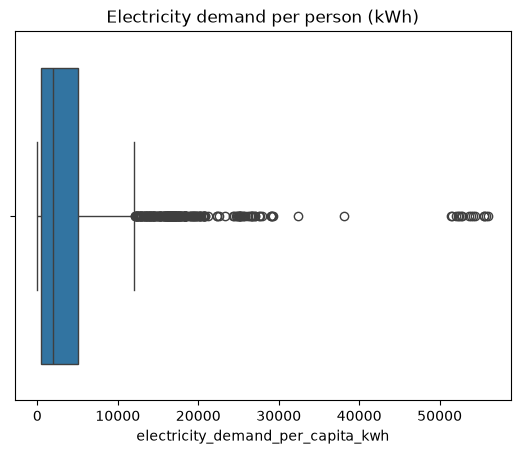

In [19]:
col = df["electricity_demand_per_capita_kwh"]
q1 = col.quantile(0.25)
q3 = col.quantile(0.75)
iqr = q3 - q1
outliers = df[(col < q1 - 1.5 * iqr) | (col > q3 + 1.5 * iqr)]
print("Outliers:", len(outliers), "of", len(df))
print(outliers["country"].value_counts().head(8))

sns.boxplot(x=col)
plt.title("Electricity demand per person (kWh)")
plt.show()

**Decision: keep them.** The outliers are real countries (for example Iceland, Norway, Canada and Gulf states) that use a lot of electricity, not data errors. Removing them would remove the extremes I want to explain. Instead, I use the **log** of demand later to reduce their effect.

### 1.6 Check the final size

In [20]:
print("Final data:", df.shape[0], "rows and", df.shape[1], "columns")
print("Countries:", df["country"].nunique(), "| years:", df["year"].min(), "to", df["year"].max())
print("At least 3000 rows and 7 columns?", df.shape[0] >= 3000 and df.shape[1] >= 7)

Final data: 3547 rows and 20 columns
Countries: 159 | years: 2000 to 2022
At least 3000 rows and 7 columns? True


**Challenges:** totals mixed with countries; many missing values (dropping them reduces the data and mostly removes small or poorly reported countries, so results lean towards better reported countries), very skewed values and shares that add up to about 100 %, which makes them partly dependent on each other.

## 2. Exploratory data analysis

### Q1. How has the share of renewable electricity changed over time?

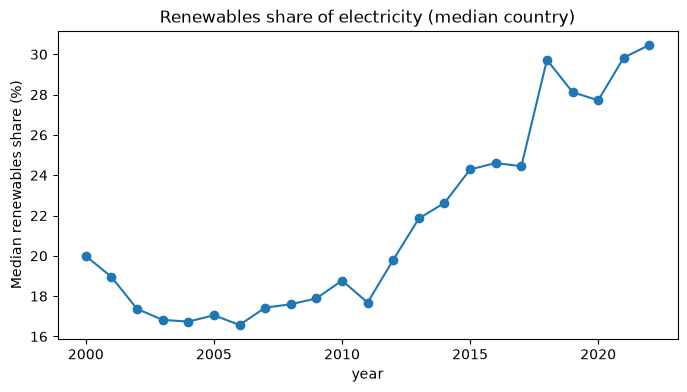

year
2000    20.0
2006    16.6
2010    18.8
2011    17.7
2020    27.7
2022    30.5
Name: renewables_electricity_share_pct, dtype: float64


In [32]:
by_year = df.groupby("year")["renewables_electricity_share_pct"].median()
by_year.plot(marker="o", figsize=(8, 4))
plt.ylabel("Median renewables share (%)")
plt.title("Renewables share of electricity (median country)")
plt.show()
print(by_year.loc[[2000,2006,2010,2011,2020,2022]].round(1))

**What it shows:** The median country's renewable electricity share dipped from **20.0%** in 2000 to **18.8%** in 2010, reaching a low of about **16.6%** in 2006. It then rose strongly after 2011, to **27.7%** in 2020 and **30.5%** in 2022. This is consistent with the growth of wind and solar in recent years, but the chart covers all renewables and only the countries in the cleaned sample, so it does not describe the global mix.

### Q2. Which countries use the most electricity per person?

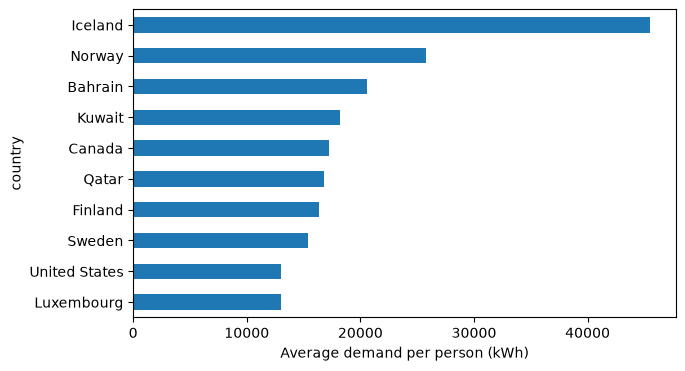

In [35]:
top = df.groupby("country")["electricity_demand_per_capita_kwh"].mean().sort_values().tail(10)
top.plot(kind="barh", figsize=(7, 4))
plt.xlabel("Average demand per person (kWh)")
plt.show()

**What it shows:** a few small, rich or cold countries with cheap power are far above everyone else. These are the outliers kept in Section 1.5.

### Q3. How are income, demand and carbon intensity related?

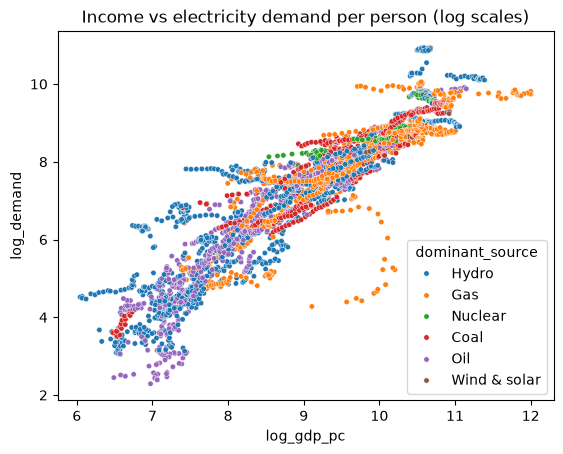

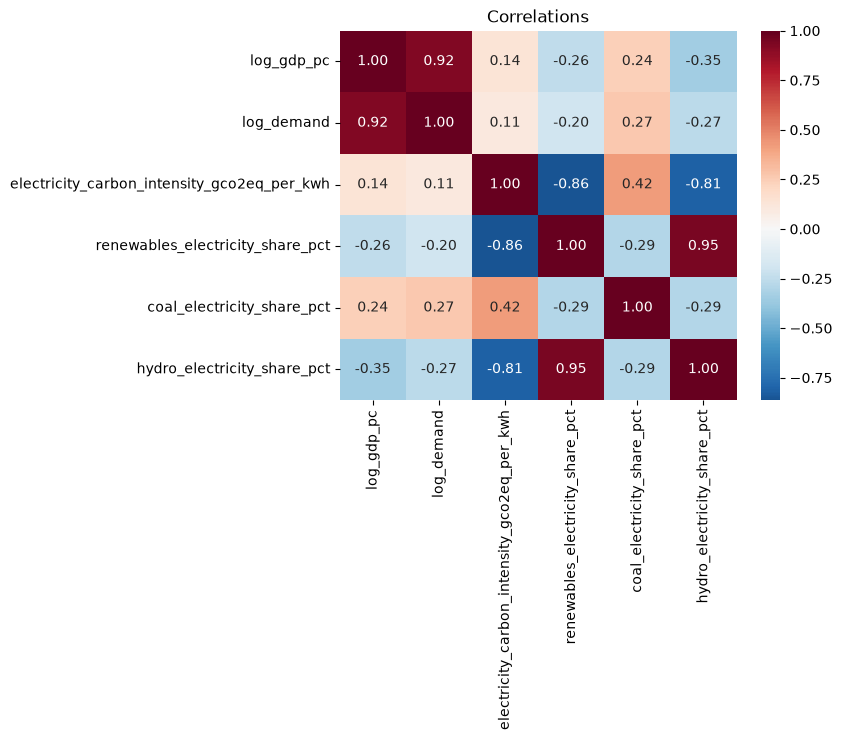

In [38]:
sns.scatterplot(data=df, x="log_gdp_pc", y="log_demand", hue="dominant_source", s=15)
plt.title("Income vs electricity demand per person (log scales)")
plt.show()

cols = ["log_gdp_pc", "log_demand", "electricity_carbon_intensity_gco2eq_per_kwh",
        "renewables_electricity_share_pct", "coal_electricity_share_pct", "hydro_electricity_share_pct"]
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlations")
plt.show()

**What it shows:**
- **Income vs. demand (`r = 0.92`):** Richer countries use much more electricity per person.
- **Income vs. carbon intensity (`r = 0.14`):** There is almost no link between wealth and grid cleanliness .A rich country is not automatically a clean one.
- **Generation mix vs. carbon intensity:** Carbon intensity drops sharply as renewables (`r = -0.86`) and hydro (`r = -0.81`) increase, and rises with coal (`r = 0.42`). Correlation does not prove cause.

### Q4. Does carbon intensity depend on the main source?

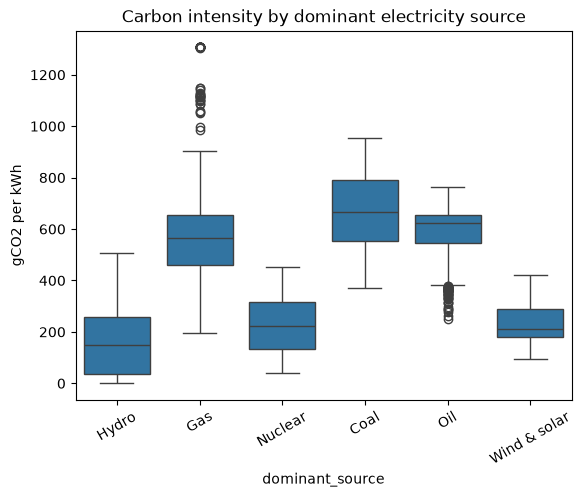

In [40]:
sns.boxplot(data=df, x="dominant_source", y="electricity_carbon_intensity_gco2eq_per_kwh")
plt.title("Carbon intensity by dominant electricity source")
plt.ylabel("gCO2 per kWh")
plt.xticks(rotation=30)
plt.show()

**Findings** coal, oil and gas systems have much higher carbon intensity than hydro, nuclear, and wind and solar systems, as expected.

**Limitations of the EDA:** the data are yearly totals for whole countries, so differences inside a country are hidden; countries report data differently; and the same country appears in many years, so rows are not independent.

## 3. Encoding and PCA

### 3.1 Encoding
dominant_source is a category with no order, so I use **one-hot encoding** (one 0/1 column per category) perriod has a natural order, so I use **label encoding** (0, 1, 2).

In [43]:
# One-hot encode dominant_source (nominal - no natural order)
onehot = pd.get_dummies(df["dominant_source"], prefix="main", dtype=int)
print(onehot.head(3))

# Label encode period (ordinal - preserves chronological order)
df["period_code"] = df["period"].map({"2000-2009": 0, "2010-2019": 1, "2020-2024": 2})
print(df[["period", "period_code"]].drop_duplicates())

     main_Coal  main_Gas  main_Hydro  main_Nuclear  main_Oil  \
126          0         0           1             0         0   
127          0         0           1             0         0   
128          0         0           1             0         0   

     main_Wind & solar  
126                  0  
127                  0  
128                  0  
        period period_code
126  2000-2009           0
136  2010-2019           1
146  2020-2024           2


### 3.2 Choosing features and standardization
PCA uses 9 numeric features. The one-hot columns are not included in PCA because they are made from the share columns already used (it would repeat information). **Standardising** is needed because the features have very different scales (carbon intensity is in the hundreds, shares are 0 to 100).

In [45]:
features = ["coal_electricity_share_pct", "gas_electricity_share_pct",
            "oil_electricity_share_pct", "nuclear_electricity_share_pct",
            "hydro_electricity_share_pct", "wind_solar_share_pct",
            "log_demand", "log_gdp_pc",
            "electricity_carbon_intensity_gco2eq_per_kwh"]

X = df[features]
X_scaled = StandardScaler().fit_transform(X)    # mean 0, standard deviation 1

pca = PCA()
scores = pca.fit_transform(X_scaled)
print("Number of features:", len(features))

Number of features: 9


### 3.3 How much variance does each component explain?

   Component  Explained %  Cumulative %
0          1         32.0          32.0
1          2         23.2          55.2
2          3         13.6          68.8
3          4         12.2          81.0
4          5         10.4          91.4
5          6          7.0          98.4
6          7          0.9          99.2
7          8          0.6          99.9
8          9          0.1         100.0


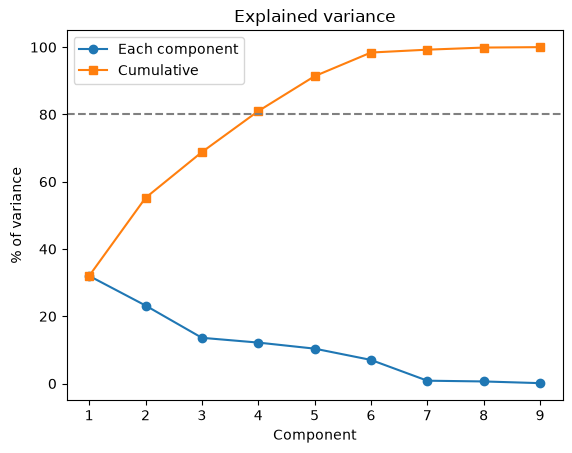

Components needed to reach 80%: 4


In [47]:
explained = pca.explained_variance_ratio_ * 100
cumulative = explained.cumsum()
table = pd.DataFrame({"Component": range(1, len(explained) + 1),
                      "Explained %": explained.round(1),
                      "Cumulative %": cumulative.round(1)})
print(table)

plt.plot(range(1, len(explained) + 1), explained, marker="o", label="Each component")
plt.plot(range(1, len(explained) + 1), cumulative, marker="s", label="Cumulative")
plt.axhline(80, linestyle="--", color="grey")
plt.xlabel("Component"); plt.ylabel("% of variance")
plt.legend(); plt.title("Explained variance")
plt.show()

n_keep = int((cumulative < 80).sum() + 1)
print("Components needed to reach 80%:", n_keep)

**How many to keep?** I keep **4 components**, which explain **81.0%** of the variance and pass the 80% target. Although 6 components capture 98.4% before the drop-off at component 7, 4 is the simpler choice that retains most of the information without adding extra dimensions.

### 3.4 What do the components mean? (loadings)

                                              PC1   PC2   PC3
coal_electricity_share_pct                   0.28  0.06 -0.44
gas_electricity_share_pct                    0.29  0.11  0.74
oil_electricity_share_pct                   -0.18  0.49 -0.28
nuclear_electricity_share_pct                0.21 -0.29 -0.32
hydro_electricity_share_pct                 -0.39 -0.46  0.12
wind_solar_share_pct                         0.16 -0.16 -0.25
log_demand                                   0.49 -0.23 -0.01
log_gdp_pc                                   0.51 -0.21  0.01
electricity_carbon_intensity_gco2eq_per_kwh  0.29  0.58  0.02


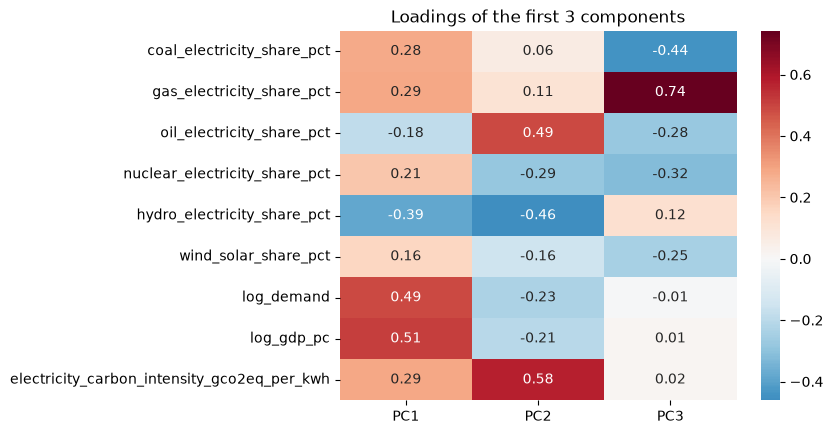

In [48]:
loadings = pd.DataFrame(pca.components_[:3].T, index=features, columns=["PC1", "PC2", "PC3"])
print(loadings.round(2))

sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Loadings of the first 3 components")
plt.show()

**What the components represent:**
- **PC1 (Wealth and demand):** High scores mean higher income (0.51) and higher electricity demand (0.49), while low scores mean a higher share of hydro (-0.39).
- **PC2 (Carbon intensity):** High scores mean higher carbon intensity (0.58) and more oil (0.49), while low scores mean more hydro (-0.46) and nuclear (-0.29).
- **PC3 (Gas vs. coal and nuclear):** High scores mean a higher share of gas (0.74), while low scores mean more coal (-0.44) and nuclear (-0.32).

### 3.5 Plot the countries on the first two components

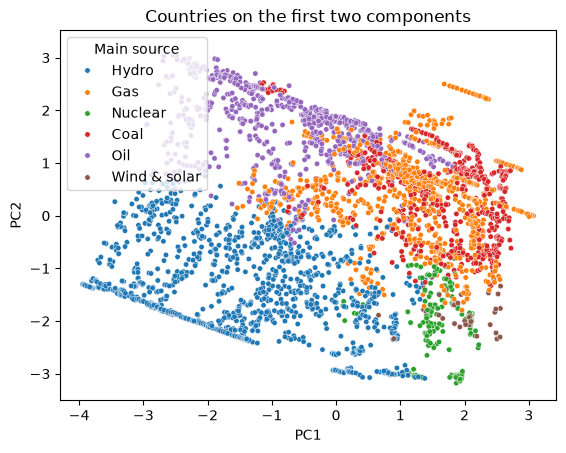

In [49]:
plot_df = pd.DataFrame({"PC1": scores[:, 0], "PC2": scores[:, 1],
                        "Main source": df["dominant_source"].values})
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Main source", s=15)
plt.title("Countries on the first two components")
plt.show()

The dominant-source colours were not used to build the PCA, yet they group together, so the components capture real differences between electricity systems.

### 3.6 Benefits and limitations of PCA here
**Benefits:** 9 related measures become a few uncorrelated components; it shows the main differences in one picture; it removes repeated information.

**Limitations:** components are mixtures of features, so they are harder to explain; PCA finds variance, not necessarily what matters for policy; shares add up to about 100 %, which forces some loadings to be negative; and the same country appears many times.

### 4. Conclusion
**Data:** After cleaning, 3,547 rows and 20 columns across 159 countries (2000 to 2022).

**Findings:**
1. The median country's renewable share fell from 20.0% in 2000 to 16.6% in 2006, then rose to 30.5% by 2022.
2. Electricity use per person rises strongly with income (r = 0.92), but a rich country is not automatically low-carbon (r = 0.14).
3. Carbon intensity is much higher where coal, oil, or gas dominate (median about 570 to 670 gCO2/kWh) than where hydro, nuclear, or wind and solar dominate (about 150 to 225).
4. PCA reduces nine features to four components explaining 81.0% of the variance, led by a wealth and demand axis (PC1) and a carbon intensity axis (PC2).

**Answer to the research question:** Countries differ mainly in how much electricity they use, which follows income, and separately in how it is generated, which sets its carbon intensity. Wealth alone does not make a grid low-carbon.

**Limitations:** Yearly country totals hide differences inside countries; dropping missing values favours well-reported countries; shares add up to about 100%; the same country appears in many years; high-demand outliers were kept because they are real countries; and all findings show association, not cause.


### 5. References


Jolliffe, I.T. and Cadima, J. (2016) 'Principal component analysis: a review and recent developments', *Philosophical Transactions of the Royal Society A*, 374(2065), 20150202. Available at: https://doi.org/10.1098/rsta.2015.0202 (Accessed: 16 November 2026).

Pedregosa, F. et al. (2011) 'Scikit-learn: machine learning in Python', *Journal of Machine Learning Research*, 12(85), pp. 2825–2830. Available at: https://jmlr.org/papers/v12/pedregosa11a.html (Accessed: 9 November 2026).

Ritchie, H., Rosado, P. and Roser, M. (2023) 'Energy', *Our World in Data*. Available at: https://ourworldindata.org/energy (Accessed: 4 November 2026).

Our World in Data (n.d.) *Energy dataset* [Dataset]. Available at: https://github.com/owid/energy-data (Accessed: 4 November 2026).